# A7 — Multi-Model AI Systems

Person 1 supplies the shared contract and SLM foundation. Architecture lead integrates the team evidence, architecture, costs and routing analysis. Original experiments are preserved below. Missing results are explicitly reported.

In [1]:
from pathlib import Path
import sys
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "a7" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from a7.benchmark_contract import (
    EVALUATION_CRITERIA, MODEL_REGISTRY, PROMPTS, render_prompt, validate_contract
)
from a7.benchmark_runner import RESULT_COLUMNS, select_models, validate_result_rows

validate_contract()
print("Shared A7 contract validated.")

Shared A7 contract validated.


## 1. Model registry and allocation

The five fixed A6 size categories contain exactly three models each. Benchmark ownership is distributed 4/4/4/3 by round-robin parameter rank so members do not receive only one size class. All model links point to their Hugging Face cards.

In [2]:
registry_df = pd.DataFrame(MODEL_REGISTRY)
display(registry_df[["category", "model_id", "params_b", "owner", "model_card"]])
display(registry_df.groupby("category").agg(models=("model_id", "count"), min_params_b=("params_b", "min"), max_params_b=("params_b", "max")))
display(registry_df.groupby("owner").agg(models=("model_id", "count"), categories=("category", "nunique")))

,category,model_id,params_b,owner,model_card
0,Ultra-light (<0.2B),distilbert/distilgpt2,0.082,P1,https://huggingface.co/distilbert/distilgpt2
1,Ultra-light (<0.2B),facebook/opt-125m,0.125,P2,https://huggingface.co/facebook/opt-125m
2,Ultra-light (<0.2B),HuggingFaceTB/SmolLM2-135M-Instruct,0.135,P3,https://huggingface.co/HuggingFaceTB/SmolLM2-1...
3,Compact (0.2B–<0.6B),HuggingFaceTB/SmolLM-360M-Instruct,0.360,architecture,https://huggingface.co/HuggingFaceTB/SmolLM-36...
4,Compact (0.2B–<0.6B),HuggingFaceTB/SmolLM2-360M-Instruct,0.360,P1,https://huggingface.co/HuggingFaceTB/SmolLM2-3...
5,Compact (0.2B–<0.6B),Qwen/Qwen2-0.5B-Instruct,0.494,P2,https://huggingface.co/Qwen/Qwen2-0.5B-Instruct
6,Small (0.6B–<1.6B),Qwen/Qwen3-0.6B,0.600,P3,https://huggingface.co/Qwen/Qwen3-0.6B
7,Small (0.6B–<1.6B),TinyLlama/TinyLlama-1.1B-Chat-v1.0,1.100,architecture,https://huggingface.co/TinyLlama/TinyLlama-1.1...
8,Small (0.6B–<1.6B),Qwen/Qwen2.5-1.5B-Instruct,1.540,P1,https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct
9,Medium (1.6B–<3.5B),HuggingFaceTB/SmolLM2-1.7B-Instruct,1.700,P2,https://huggingface.co/HuggingFaceTB/SmolLM2-1...


,models,min_params_b,max_params_b
category,,,
Compact (0.2B–<0.6B),3,0.360,0.494
Large (≥3.5B),3,3.820,7.620
Medium (1.6B–<3.5B),3,1.700,3.210
Small (0.6B–<1.6B),3,0.600,1.540
Ultra-light (<0.2B),3,0.082,0.135


,models,categories
owner,,
P1,4,4
P2,4,4
P3,4,4
architecture,3,3


## 2. Fixed task-specific prompt matrix

Hestia's five prompt types are structured extraction, classification, priority prediction, summarization, and action planning. Each type has five realistic household inputs, producing 25 prompts per model and 375 evaluations overall.

In [3]:
prompts_df = pd.DataFrame(PROMPTS)
prompt_counts = prompts_df.groupby("prompt_type").size().rename("prompts")
display(prompt_counts)
display(prompts_df)
print("Example rendered prompt:\n")
print(render_prompt(PROMPTS[0]))

prompt_type
action_planning          5
classification           5
priority_prediction      5
structured_extraction    5
summarization            5
Name: prompts, dtype: int64

,prompt_id,prompt_type,input
0,extraction-01,structured_extraction,"Guests arrive tomorrow. Clean the kitchen, buy..."
1,extraction-02,structured_extraction,"This week I need to book the dentist, replace ..."
2,extraction-03,structured_extraction,"Before Saturday, vacuum the living room and pi..."
3,extraction-04,structured_extraction,Please remind us to pay the electricity bill t...
4,extraction-05,structured_extraction,The refrigerator is making noise. Also organiz...
5,classification-01,classification,Buy milk and rice after work.
6,classification-02,classification,Call the plumber about the dripping kitchen pipe.
7,classification-03,classification,Schedule a yearly dental cleaning.
8,classification-04,classification,Submit the apartment renewal form by Friday.
9,classification-05,classification,Sweep the porch and empty the recycling.


Example rendered prompt:

You are Hestia, a household coordination assistant. Do not invent private details or claim that an action is complete.
Return JSON only: {"tasks":[{"title":"...","task_type":"CHORE|APPOINTMENT|DEADLINE|ERRAND|MAINTENANCE|SHOPPING|OTHER","priority":"LOW|MEDIUM|HIGH|URGENT","description":"..."}]}. Create one task per concern.
Household request: Guests arrive tomorrow. Clean the kitchen, buy snacks, and fix the leaking bathroom tap.
Answer:


## 3. Self-evaluation rubric

Every output is assessed against the same five criteria. Person 1's original heuristic scores were inspected semantically by the assistant; the student authorized applying 42 corrected totals. This is not a claim of personal student inspection. The original scores, response hashes, all 100 assessments and scoring conventions are preserved under `person1/review/`. No generation output or timing was altered. Cross-owner format/scoring conventions still need reconciliation before final signoff.

In [4]:
rubric_df = pd.DataFrame(EVALUATION_CRITERIA)
display(rubric_df)
print("Maximum score:", rubric_df["max_points"].sum())

,criterion,max_points,description
0,task_accuracy,3,Correctly addresses the household request with...
1,instruction_adherence,2,Follows the requested task and output instruct...
2,completeness,2,Includes all essential requested information.
3,clarity,2,"Produces concise, understandable, usable text."
4,no_unsupported_details,1,"Avoids invented facts, dates, people, or requi..."


Maximum score: 10


## 4. Person 1 experiment

Person 1 runs four models across four size categories on the same Apple MPS environment. The runner uses deterministic greedy generation with a fixed 220-token limit, checkpoints after each response, and records latency, generated tokens, and tokens per second.

In [5]:
person1_models = select_models(owner="P1")
display(pd.DataFrame(person1_models)[["category", "model_id", "params_b", "model_card"]])
print("Expected evaluations:", len(person1_models) * len(PROMPTS))

,category,model_id,params_b,model_card
0,Ultra-light (<0.2B),distilbert/distilgpt2,0.082,https://huggingface.co/distilbert/distilgpt2
1,Compact (0.2B–<0.6B),HuggingFaceTB/SmolLM2-360M-Instruct,0.360,https://huggingface.co/HuggingFaceTB/SmolLM2-3...
2,Small (0.6B–<1.6B),Qwen/Qwen2.5-1.5B-Instruct,1.540,https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct
3,Large (≥3.5B),microsoft/Phi-3.5-mini-instruct,3.820,https://huggingface.co/microsoft/Phi-3.5-mini-...


Expected evaluations: 100


In [6]:
# Change to True only when intentionally regenerating all Person 1 evidence.
RUN_PERSON1_BENCHMARK = False
RESULT_PATH = REPO_ROOT / "a7" / "results" / "person1_benchmark.csv"

if RUN_PERSON1_BENCHMARK:
    from a7.benchmark_runner import run_matrix
    rows = run_matrix(person1_models, RESULT_PATH, device_request="auto", max_new_tokens=220)
    print(f"Saved {len(rows)} raw evaluations to {RESULT_PATH}")
else:
    print("Using the checked-in Person 1 evidence; generation is disabled in this notebook run.")

Using the checked-in Person 1 evidence; generation is disabled in this notebook run.


## 5. Evidence review and summary

The checked-in CSV contains actual raw outputs and completed rubric fields. The cell below validates the exact 100-row Person 1 matrix, confirms the common generation limit, shows every response and review note, and summarizes measured speed and quality.

In [7]:
if RESULT_PATH.exists():
    person1_results = pd.read_csv(RESULT_PATH, keep_default_na=False)
    validate_result_rows(person1_results.to_dict("records"), person1_models, PROMPTS)
    numeric = ["latency_seconds", "output_tokens", "tokens_per_second", "self_evaluation_score_1_to_10", "max_new_tokens"]
    for column in numeric:
        person1_results[column] = pd.to_numeric(person1_results[column], errors="coerce")
    assert len(person1_results) == 100
    assert person1_results["status"].eq("ok").all()
    assert person1_results["self_evaluation_score_1_to_10"].notna().all()
    assert set(person1_results["max_new_tokens"]) == {220}
    display(person1_results)
    person1_summary = person1_results.groupby(["model_category", "model_id"]).agg(
        evaluations=("prompt_id", "count"),
        mean_latency_seconds=("latency_seconds", "mean"),
        mean_tokens_per_second=("tokens_per_second", "mean"),
        mean_quality=("self_evaluation_score_1_to_10", "mean"),
    ).round(3)
    display(person1_summary)
else:
    raise FileNotFoundError("Run the Person 1 benchmark before submission.")

,model_id,model_category,owner,prompt_id,prompt_type,prompt,latency_seconds,output_tokens,tokens_per_second,generated_output,...,device,max_new_tokens,generated_at_utc,task_accuracy_0_to_3,instruction_adherence_0_to_2,completeness_0_to_2,clarity_0_to_2,no_unsupported_details_0_to_1,self_evaluation_score_1_to_10,review_notes
0,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-01,structured_extraction,"Guests arrive tomorrow. Clean the kitchen, buy...",1.1112,220,197.9886,"""No, you're not here. You're here. You're here...",...,mps,220,2026-10-23T17:28:35.817226+00:00,0,0,0,0,0,1,AI-assisted semantic review; application autho...
1,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-02,structured_extraction,"This week I need to book the dentist, replace ...",0.8068,220,272.6956,I am not a dentist. I am a dentist. I am a den...,...,mps,220,2026-10-23T17:28:36.626639+00:00,0,0,0,0,0,1,AI-assisted semantic review; application autho...
2,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-03,structured_extraction,"Before Saturday, vacuum the living room and pi...",1.2996,220,169.2817,"If you have a problem with the door, you can c...",...,mps,220,2026-10-23T17:28:37.927594+00:00,0,0,0,0,0,1,AI-assisted semantic review; application autho...
3,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-04,structured_extraction,Please remind us to pay the electricity bill t...,0.7790,220,282.4291,We are not responsible for the amount of elect...,...,mps,220,2026-10-23T17:28:38.707972+00:00,0,0,0,0,0,1,AI-assisted semantic review; application autho...
4,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-05,structured_extraction,The refrigerator is making noise. Also organiz...,0.8053,220,273.1813,The refrigerator is making noise. Also organiz...,...,mps,220,2026-10-23T17:28:39.514719+00:00,0,0,0,0,0,1,AI-assisted semantic review; application autho...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),P1,planning-01,action_planning,Prepare the apartment for overnight guests tom...,19.5454,220,11.2558,"{""steps"":[""Step 1: Ensure all cleaning supplie...",...,mps,220,2026-10-23T17:34:22.115928+00:00,3,0,2,1,1,7,AI-assisted semantic review; application autho...
96,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),P1,planning-02,action_planning,Organize a weekly grocery trip while staying u...,20.4956,220,10.7340,"{""steps"":[""Step 1: Create a grocery list categ...",...,mps,220,2026-10-23T17:34:42.614711+00:00,3,0,2,1,1,7,AI-assisted semantic review; application autho...
97,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),P1,planning-03,action_planning,Deep-clean the kitchen safely in one afternoon.,14.6461,168,11.4706,"{""steps"":[""Step 1: Gather all necessary cleani...",...,mps,220,2026-10-23T17:34:57.266686+00:00,3,2,2,2,1,10,AI-assisted semantic review; application autho...
98,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),P1,planning-04,action_planning,Get ready for a move to a new apartment next m...,20.0580,220,10.9682,"{""steps"":[""Step 1: Create a detailed checklist...",...,mps,220,2026-10-23T17:35:17.327996+00:00,2,0,1,1,1,5,AI-assisted semantic review; application autho...


,,evaluations,mean_latency_seconds,mean_tokens_per_second,mean_quality
model_category,model_id,,,,
Compact (0.2B–<0.6B),HuggingFaceTB/SmolLM2-360M-Instruct,25,1.602,49.959,3.32
Large (≥3.5B),microsoft/Phi-3.5-mini-instruct,25,10.567,10.551,7.00
Small (0.6B–<1.6B),Qwen/Qwen2.5-1.5B-Instruct,25,2.635,19.647,6.60
Ultra-light (<0.2B),distilbert/distilgpt2,25,0.836,268.325,1.00


## 6. Person 1 corrected findings

After the authorized AI-assisted corrections, mean scores are **Phi-3.5-mini 7.00**, **Qwen2.5-1.5B 6.60**, **SmolLM2-360M 3.32**, and **distilgpt2 1.00**. Phi now has the highest mean in this four-model subset, while Qwen has lower median latency (1.5895 seconds versus 5.3627 seconds). This is a quality/speed tradeoff, not a single overall winner.

Qwen still beats Phi on six matched prompts, including extraction-02 (8 versus 5), so larger models do not always win. Prompt echoes no longer receive task-completion credit; faithful synonyms receive credit; fences and extra continuations prevent full JSON-only compliance. None of the Person 1 models passes every format check across a complete five-prompt task group under the current gate. Use the full 15-model results below for team conclusions. The source outputs and timing measurements remain unchanged.

## Assignment 2 — Person 1 SLM experiments

The class notebook has now been supplied. `slm/slm_experiments.ipynb` contains the
executed original baseline, five independent architecture experiments, four
temperature tests and evidence-based Part 1 analysis. The original class source is
preserved in `slm/class_source.ipynb`; `slm/HANDOFF.md` explains how Persons 2 and 3
load the same selected baseline checkpoint. Weight files are not committed.

## Architecture lead — integrated evidence and coverage

Successful, reviewed results are required for all 375 model/prompt pairs. A failed download is not an evaluated response. Timings from different machines are not directly comparable, even if both use the same device label.

In [8]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'a7/benchmark_contract.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from a7.architecture_analysis import write_analysis
data, coverage, models, categories, costs, cost_status = write_analysis(ROOT)
display(coverage)
print('Successful evaluations:', int(coverage.successful.sum()), '/ 375')
print('Scored successful evaluations:', int(coverage.scored.sum()), '/ 375')
display(models)
display(categories)


,owner,expected,recorded,successful,scored,missing,remaining_successful
0,P1,100,100,100,100,0,0
1,P2,100,100,100,100,0,0
2,P3,100,100,100,100,0,0
3,architecture,75,75,75,75,0,0


Successful evaluations: 375 / 375
Scored successful evaluations: 375 / 375


,model_id,model_category,device,benchmark_condition,max_new_tokens,evaluations,scored,mean_quality,median_latency_s,p95_latency_s,median_tokens_s
0,HuggingFaceTB/SmolLM-360M-Instruct,Compact (0.2B–<0.6B),cpu,Windows CPU / native FP32 / 4 threads,220,25,25,2.48,19.0588,19.95602,11.4717
1,HuggingFaceTB/SmolLM2-1.7B-Instruct,Medium (1.6B–<3.5B),cuda,Tesla T4 / NF4 weights / float32 compute / eager,220,25,25,4.96,0.8802,6.78640,20.5394
2,HuggingFaceTB/SmolLM2-135M-Instruct,Ultra-light (<0.2B),mps,Person 3 macOS arm64 / mps / float16 / 16 GB u...,220,25,25,2.56,1.6161,5.45758,37.1266
3,HuggingFaceTB/SmolLM2-360M-Instruct,Compact (0.2B–<0.6B),mps,Apple MPS / native model / exact GPU unrecorded,220,25,25,3.32,0.5633,4.17766,50.8544
4,Qwen/Qwen2-0.5B-Instruct,Compact (0.2B–<0.6B),cuda,Tesla T4 / NF4 weights / float32 compute / eager,220,25,25,5.20,1.4941,4.74612,22.4989
5,Qwen/Qwen2.5-1.5B-Instruct,Small (0.6B–<1.6B),mps,Apple MPS / native model / exact GPU unrecorded,220,25,25,6.60,1.5895,7.66020,22.0191
6,Qwen/Qwen2.5-3B-Instruct,Medium (1.6B–<3.5B),mps,Person 3 macOS arm64 / mps / float16 / 16 GB u...,220,25,25,7.72,5.7808,22.81772,6.3267
7,Qwen/Qwen2.5-7B-Instruct,Large (≥3.5B),mlx-4bit,Person 3 macOS arm64 / mlx-4bit / 4-bit / 16 G...,220,25,25,7.32,1.6516,8.97480,15.2112
8,Qwen/Qwen3-0.6B,Small (0.6B–<1.6B),mps,Person 3 macOS arm64 / mps / float16 / 16 GB u...,220,25,25,6.36,1.2654,4.36840,23.9105
9,TinyLlama/TinyLlama-1.1B-Chat-v1.0,Small (0.6B–<1.6B),cuda,Tesla T4 / native FP16,220,25,25,2.96,5.2453,5.91038,37.7479


,model_category,models,evaluations,scored,mean_quality,expected_evaluations
0,Compact (0.2B–<0.6B),3,75,75,3.666667,75
1,Large (≥3.5B),3,75,75,7.480000,75
2,Medium (1.6B–<3.5B),3,75,75,6.520000,75
3,Small (0.6B–<1.6B),3,75,75,5.306667,75
4,Ultra-light (<0.2B),3,75,75,1.546667,75


### Step 1.6: performance analysis

Category means are preliminary until each category has 75 successful reviewed evaluations. Determine whether larger models always win by checking matched prompts, not by assuming parameter count determines quality. The best speed/quality choice must satisfy the task quality threshold and be timed on the same hardware. The next cell shows available evidence without declaring a global speed winner.

In [9]:
if not models.empty:
    display(models.sort_values('mean_quality', ascending=False))
    display(data[data.status.eq('ok')].groupby(['model_id', 'prompt_type'])[
        'self_evaluation_score_1_to_10'].agg(['count', 'mean']))
if coverage.successful.sum() < 375 or coverage.scored.sum() < 375:
    print('PENDING: complete and manually review all team results before final conclusions.')


,model_id,model_category,device,benchmark_condition,max_new_tokens,evaluations,scored,mean_quality,median_latency_s,p95_latency_s,median_tokens_s
14,mistralai/Mistral-7B-Instruct-v0.3,Large (≥3.5B),cuda,Tesla T4 / NF4 weights / float32 compute / eager,220,25,25,8.12,4.1807,18.09384,9.5678
6,Qwen/Qwen2.5-3B-Instruct,Medium (1.6B–<3.5B),mps,Person 3 macOS arm64 / mps / float16 / 16 GB u...,220,25,25,7.72,5.7808,22.81772,6.3267
7,Qwen/Qwen2.5-7B-Instruct,Large (≥3.5B),mlx-4bit,Person 3 macOS arm64 / mlx-4bit / 4-bit / 16 G...,220,25,25,7.32,1.6516,8.97480,15.2112
13,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),mps,Apple MPS / native model / exact GPU unrecorded,220,25,25,7.00,5.3627,20.49218,10.8810
12,meta-llama/Llama-3.2-3B-Instruct,Medium (1.6B–<3.5B),cuda,Tesla T4 / native FP16,220,25,25,6.88,1.0295,4.98346,26.2267
5,Qwen/Qwen2.5-1.5B-Instruct,Small (0.6B–<1.6B),mps,Apple MPS / native model / exact GPU unrecorded,220,25,25,6.60,1.5895,7.66020,22.0191
8,Qwen/Qwen3-0.6B,Small (0.6B–<1.6B),mps,Person 3 macOS arm64 / mps / float16 / 16 GB u...,220,25,25,6.36,1.2654,4.36840,23.9105
4,Qwen/Qwen2-0.5B-Instruct,Compact (0.2B–<0.6B),cuda,Tesla T4 / NF4 weights / float32 compute / eager,220,25,25,5.20,1.4941,4.74612,22.4989
1,HuggingFaceTB/SmolLM2-1.7B-Instruct,Medium (1.6B–<3.5B),cuda,Tesla T4 / NF4 weights / float32 compute / eager,220,25,25,4.96,0.8802,6.78640,20.5394
3,HuggingFaceTB/SmolLM2-360M-Instruct,Compact (0.2B–<0.6B),mps,Apple MPS / native model / exact GPU unrecorded,220,25,25,3.32,0.5633,4.17766,50.8544


count  mean
model_id                           prompt_type                       
HuggingFaceTB/SmolLM-360M-Instruct action_planning            5   2.8
                                   classification             5   1.0
                                   priority_prediction        5   1.0
                                   structured_extraction      5   3.2
                                   summarization              5   4.4
...                                                         ...   ...
mistralai/Mistral-7B-Instruct-v0.3 action_planning            5   8.2
                                   classification             5  10.0
                                   priority_prediction        5   5.8
                                   structured_extraction      5   7.4
                                   summarization              5   9.2

[75 rows x 2 columns]

# Available benchmark findings

375/375 successful, scored evaluations are available across 15/15 models. Scores are assistant-assessed; student signoff remains pending. Hardware/precision conditions are separate; this is not a controlled size-only experiment.

| Model | Condition | Mean quality /10 | Median latency (s) |
|---|---|---|---|
| mistralai/Mistral-7B-Instruct-v0.3 | Tesla T4 / NF4 weights / float32 compute / eager | 8.12 | 4.1807 |
| Qwen/Qwen2.5-3B-Instruct | Person 3 macOS arm64 / mps / float16 / 16 GB unified memory | 7.72 | 5.7808 |
| Qwen/Qwen2.5-7B-Instruct | Person 3 macOS arm64 / mlx-4bit / 4-bit / 16 GB unified memory | 7.32 | 1.6516 |
| microsoft/Phi-3.5-mini-instruct | Apple MPS / native model / exact GPU unrecorded | 7.00 | 5.3627 |
| meta-llama/Llama-3.2-3B-Instruct | Tesla T4 / native FP16 | 6.88 | 1.0295 |
| Qwen/Qwen2.5-1.5B-Instruct | Apple MPS / native model / exact GPU unrecorded | 6.60 | 1.5895 |
| Qwen/Qwen3-0.6B | Person 3 macOS arm64 / mps / float16 / 16 GB unified memory | 6.36 | 1.2654 |
| Qwen/Qwen2-0.5B-Instruct | Tesla T4 / NF4 weights / float32 compute / eager | 5.20 | 1.4941 |
| HuggingFaceTB/SmolLM2-1.7B-Instruct | Tesla T4 / NF4 weights / float32 compute / eager | 4.96 | 0.8802 |
| HuggingFaceTB/SmolLM2-360M-Instruct | Apple MPS / native model / exact GPU unrecorded | 3.32 | 0.5633 |
| TinyLlama/TinyLlama-1.1B-Chat-v1.0 | Tesla T4 / native FP16 | 2.96 | 5.2453 |
| HuggingFaceTB/SmolLM2-135M-Instruct | Person 3 macOS arm64 / mps / float16 / 16 GB unified memory | 2.56 | 1.6161 |
| HuggingFaceTB/SmolLM-360M-Instruct | Windows CPU / native FP32 / 4 threads | 2.48 | 19.0588 |
| facebook/opt-125m | Tesla T4 / NF4 weights / float32 compute / eager | 1.08 | 3.1447 |
| distilbert/distilgpt2 | Apple MPS / native model / exact GPU unrecorded | 1.00 | 0.7815 |

## Step 1.6 answers

1. Best output category: Large (≥3.5B) has the highest observed mean (7.48/10) across the completed 75-row/category matrix. Quantization, instruction tuning and hardware differ, so this is descriptive rather than a size-only causal result.

| Category | Models available /3 | Rows available /75 | Mean quality /10 |
|---|---|---|---|
| Compact (0.2B–<0.6B) | 3 | 75 | 3.67 |
| Large (≥3.5B) | 3 | 75 | 7.48 |
| Medium (1.6B–<3.5B) | 3 | 75 | 6.52 |
| Small (0.6B–<1.6B) | 3 | 75 | 5.31 |
| Ultra-light (<0.2B) | 3 | 75 | 1.55 |

2. On extraction-02, Qwen2.5-1.5B scored 8; Phi-3.5-mini scored 5. The smaller Qwen model scores higher on 6 matched prompts in this pair. These are counterexamples to larger models always scoring higher.

3. Speed/quality balance: within Person 1’s MPS subset, Qwen2.5-1.5B averages 6.60/10 with median latency 1.5895 s; Phi-3.5-mini averages 7.00/10 with median latency 5.3627 s. Choose by task-specific quality and format requirements rather than declaring an overall winner from speed alone. Cross-condition times do not identify a global fastest model.

Routing candidates are in task_summary.csv. A proposed qualification requires five observations, mean score at least 8/10 and all five instruction-format scores equal to 2. Passing this small offline gate is a candidate-selection result, not production validation. Person 1 corrections were authorized for application; this is not personal student signoff. Cross-owner format/scoring conventions still need reconciliation.


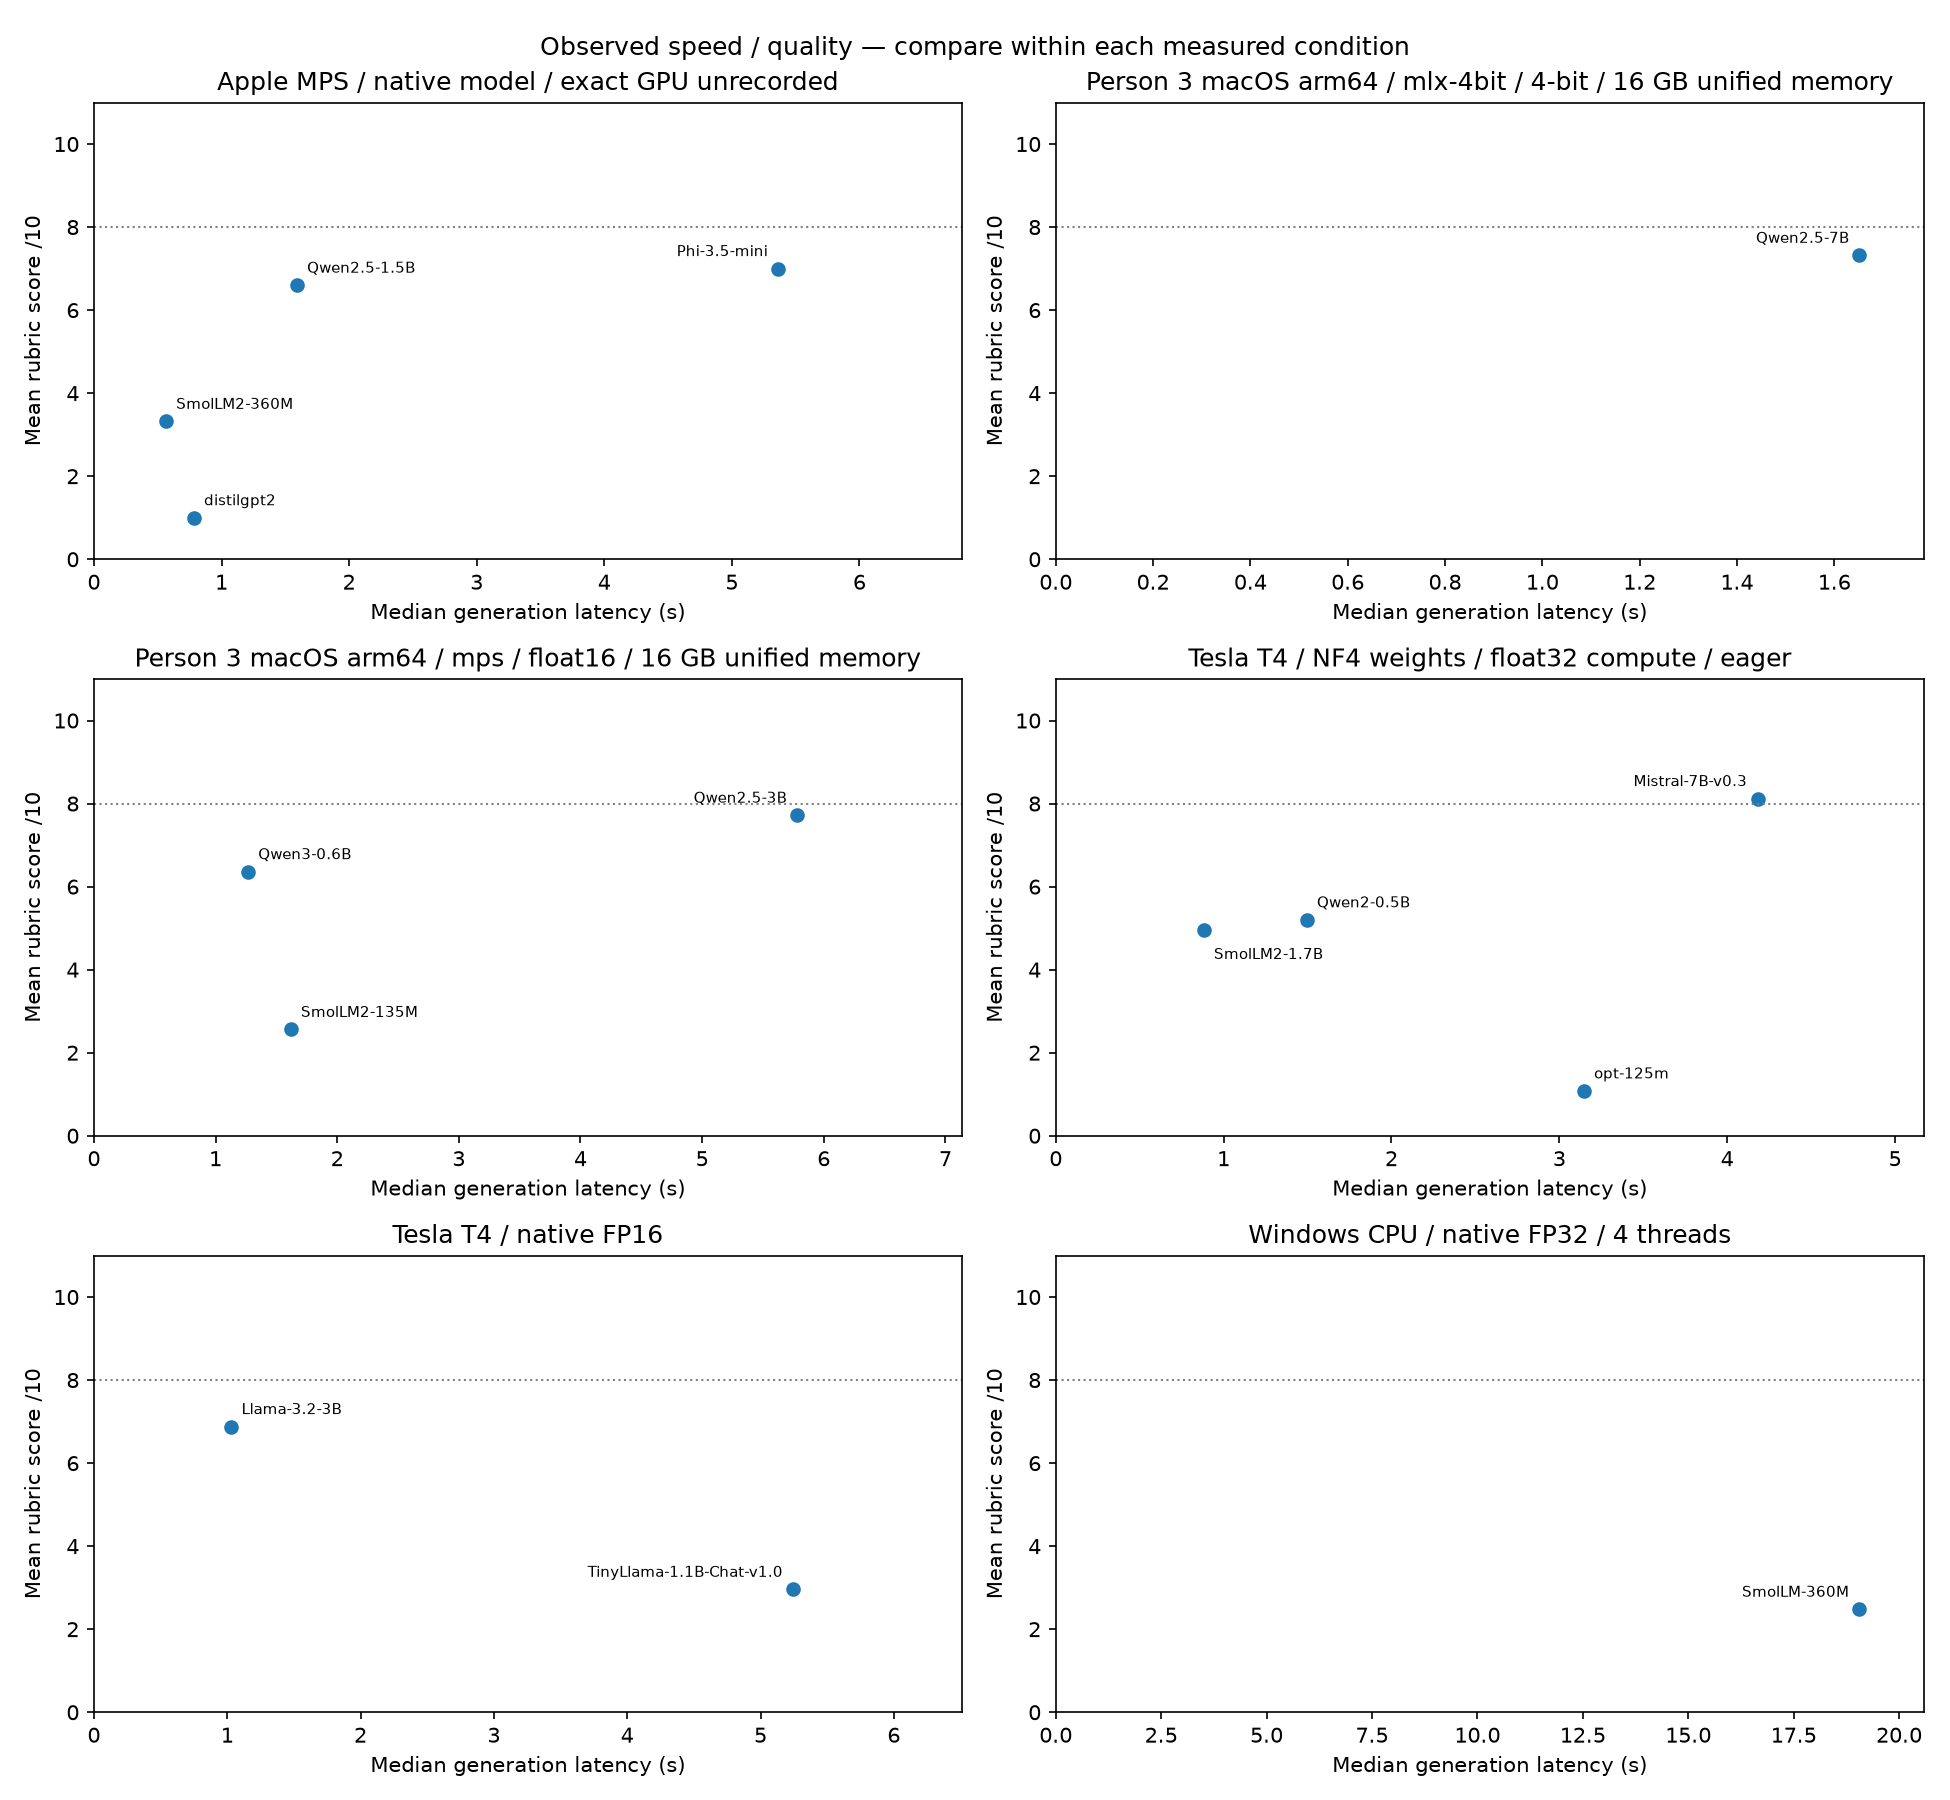

,model_id,prompt_type,benchmark_condition,evaluations,mean_quality,format_pass_rate,median_latency_s,meets_proposed_gate
31,Qwen/Qwen2.5-3B-Instruct,classification,Person 3 macOS arm64 / mps / float16 / 16 GB u...,5,10.0,1.0,1.0841,True
34,Qwen/Qwen2.5-3B-Instruct,summarization,Person 3 macOS arm64 / mps / float16 / 16 GB u...,5,9.0,1.0,5.7808,True
35,Qwen/Qwen2.5-7B-Instruct,action_planning,Person 3 macOS arm64 / mlx-4bit / 4-bit / 16 G...,5,8.4,1.0,2.3860,True
39,Qwen/Qwen2.5-7B-Instruct,summarization,Person 3 macOS arm64 / mlx-4bit / 4-bit / 16 G...,5,9.0,1.0,1.6516,True
44,Qwen/Qwen3-0.6B,summarization,Person 3 macOS arm64 / mps / float16 / 16 GB u...,5,9.4,1.0,1.2654,True
64,meta-llama/Llama-3.2-3B-Instruct,summarization,Tesla T4 / native FP16,5,9.2,1.0,1.0295,True
71,mistralai/Mistral-7B-Instruct-v0.3,classification,Tesla T4 / NF4 weights / float32 compute / eager,5,10.0,1.0,1.0496,True
74,mistralai/Mistral-7B-Instruct-v0.3,summarization,Tesla T4 / NF4 weights / float32 compute / eager,5,9.2,1.0,3.7723,True


In [10]:
display(Markdown((ROOT/'a7/results/architecture/performance_findings.md').read_text(encoding='utf-8')))
from IPython.display import Image
display(Image(filename=str(ROOT/'a7/results/architecture/speed_quality_by_condition.png')))
tasks = pd.read_csv(ROOT/'a7/results/architecture/task_summary.csv')
display(tasks[tasks.meets_proposed_gate])


## Architecture lead — Steps 2.5 and 3.1–3.3

The full five-scenario design and cost methodology are in `system_design.md`. Both normalized 90-row team tables are integrated. The API comparison uses one comparable Llama-3.1-8B/Novita rate for all 15 local alternatives, without measured quality equivalence. Routing load simulations below use explicit planning assumptions, not measured traffic or inferred savings.

In [11]:
from a7.architecture_analysis import crossover_intervals, routing_simulation
print(cost_status)
if not costs.empty:
    display(costs)
    display(crossover_intervals(costs))
    display(costs.groupby(['model_id', 'cheaper']).daily_active_users.apply(list))
simulation = routing_simulation()
display(simulation)


Validated 90 workload-aligned daily cost comparisons. API rows reuse one comparable hosted model; this is not measured quality equivalence or 15 exact-model API quotes.


,model_id,model_category_local,traffic_category,daily_active_users,requests_per_user,input_tokens_per_request,output_tokens_per_request,avg_tokens_per_user_local,total_daily_requests_local,total_daily_input_tokens_local,...,gateway_requests_per_second_assumed,machines_required_api_infrastructure,api_gateway_compute_usd_day,api_gateway_storage_usd_day,api_machine_cost_usd,total_daily_cost_usd_api,scope_api,source_or_assumption_api,local_minus_api_usd,cheaper
18,HuggingFaceTB/SmolLM-360M-Instruct,Compact (0.2B–<0.6B),Prototype,1000,1,256,500,500,1000,256000,...,50,1,1.92,0.066667,1.986667,2.016787,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,1.031655e+01,api
19,HuggingFaceTB/SmolLM-360M-Instruct,Compact (0.2B–<0.6B),Early Startup,10000,1,256,500,500,10000,2560000,...,50,1,1.92,0.066667,1.986667,2.287867,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,1.087121e+02,api
20,HuggingFaceTB/SmolLM-360M-Instruct,Compact (0.2B–<0.6B),Growing Product,100000,1,256,500,500,100000,25600000,...,50,1,1.92,0.066667,1.986667,4.998667,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,1.018668e+03,api
21,HuggingFaceTB/SmolLM-360M-Instruct,Compact (0.2B–<0.6B),Large Platform,1000000,1,256,500,500,1000000,256000000,...,50,1,1.92,0.066667,1.986667,32.106667,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,1.015523e+04,api
22,HuggingFaceTB/SmolLM-360M-Instruct,Compact (0.2B–<0.6B),Mass Consumer App,10000000,1,256,500,500,10000000,2560000000,...,50,10,19.20,0.666667,19.866667,321.066667,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,1.014783e+05,api
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,mistralai/Mistral-7B-Instruct-v0.3,Large (≥3.5B),Early Startup,10000,1,256,500,500,10000,2560000,...,50,1,1.92,0.066667,1.986667,2.287867,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,3.183788e+02,api
80,mistralai/Mistral-7B-Instruct-v0.3,Large (≥3.5B),Growing Product,100000,1,256,500,500,100000,25600000,...,50,1,1.92,0.066667,1.986667,4.998667,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,3.115335e+03,api
81,mistralai/Mistral-7B-Instruct-v0.3,Large (≥3.5B),Large Platform,1000000,1,256,500,500,1000000,256000000,...,50,1,1.92,0.066667,1.986667,32.106667,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,3.106023e+04,api
82,mistralai/Mistral-7B-Instruct-v0.3,Large (≥3.5B),Mass Consumer App,10000000,1,256,500,500,10000000,2560000000,...,50,10,19.20,0.666667,19.866667,321.066667,inference tier only; token API plus CPU gateway,hestia-a7-256in-500out-r1-inference-only-v1; w...,3.105036e+05,api


,model_id,lower_dau,upper_dau,lower_cheaper,upper_cheaper


model_id                             cheaper
HuggingFaceTB/SmolLM-360M-Instruct   api        [1000, 10000, 100000, 1000000, 10000000, 10000...
HuggingFaceTB/SmolLM2-1.7B-Instruct  api        [1000, 10000, 100000, 1000000, 10000000, 10000...
HuggingFaceTB/SmolLM2-135M-Instruct  api        [1000, 10000, 100000, 1000000, 10000000, 10000...
HuggingFaceTB/SmolLM2-360M-Instruct  api        [1000, 10000, 100000, 1000000, 10000000, 10000...
Qwen/Qwen2-0.5B-Instruct             api        [1000, 10000, 100000, 1000000, 10000000, 10000...
Qwen/Qwen2.5-1.5B-Instruct           api        [1000, 10000, 100000, 1000000, 10000000, 10000...
Qwen/Qwen2.5-3B-Instruct             api        [1000, 10000, 100000, 1000000, 10000000, 10000...
Qwen/Qwen2.5-7B-Instruct             api        [1000, 10000, 100000, 1000000, 10000000, 10000...
Qwen/Qwen3-0.6B                      api        [1000, 10000, 100000, 1000000, 10000000, 10000...
TinyLlama/TinyLlama-1.1B-Chat-v1.0   api        [1000, 10000, 100000, 100

,traffic_category,daily_active_users,scenario,assumed_requests_per_user,assumed_output_tokens,assumed_cache_fraction,assumed_local_fraction,assumed_api_fraction,assumed_peak_factor,cached_requests,local_requests,api_requests,local_output_tokens,api_output_tokens,peak_generation_requests_s,evidence_type
0,Prototype,1000,Normal operation,1,500,0.10,0.65,0.25,1,100.0,650.0,250.0,3.250000e+05,1.250000e+05,0.010417,illustrative planning assumptions
1,Prototype,1000,Evening peak,1,500,0.10,0.50,0.40,4,100.0,500.0,400.0,2.500000e+05,2.000000e+05,0.041667,illustrative planning assumptions
2,Prototype,1000,Complex household plan,1,500,0.05,0.15,0.80,1,50.0,150.0,800.0,7.500000e+04,4.000000e+05,0.010995,illustrative planning assumptions
3,Prototype,1000,Budget pressure,1,500,0.20,0.70,0.10,1,200.0,700.0,100.0,3.500000e+05,5.000000e+04,0.009259,illustrative planning assumptions
4,Prototype,1000,Local overload,1,500,0.10,0.10,0.80,4,100.0,100.0,800.0,5.000000e+04,4.000000e+05,0.041667,illustrative planning assumptions
5,Early Startup,10000,Normal operation,1,500,0.10,0.65,0.25,1,1000.0,6500.0,2500.0,3.250000e+06,1.250000e+06,0.104167,illustrative planning assumptions
6,Early Startup,10000,Evening peak,1,500,0.10,0.50,0.40,4,1000.0,5000.0,4000.0,2.500000e+06,2.000000e+06,0.416667,illustrative planning assumptions
7,Early Startup,10000,Complex household plan,1,500,0.05,0.15,0.80,1,500.0,1500.0,8000.0,7.500000e+05,4.000000e+06,0.109954,illustrative planning assumptions
8,Early Startup,10000,Budget pressure,1,500,0.20,0.70,0.10,1,2000.0,7000.0,1000.0,3.500000e+06,5.000000e+05,0.092593,illustrative planning assumptions
9,Early Startup,10000,Local overload,1,500,0.10,0.10,0.80,4,1000.0,1000.0,8000.0,5.000000e+05,4.000000e+06,0.416667,illustrative planning assumptions


### Step 2.5: conditional API price thresholds

Person 2 supplied 90 local-hosting estimates using one request/user/day, 256 input and 500 output tokens. The paired API costs above include Person 3’s gateway estimates. As a separate sensitivity analysis, the next table computes the API price that would tie each local estimate assuming a zero-cost API gateway, an optimistic API bound. These are conditional thresholds, not paid API rates or observed DAU crossovers. For nonzero gateway cost A/day, subtract A from local daily cost before dividing by daily output tokens. The paired results show API cheaper in all 90 modeled cases; no crossover is observed.

,model_id,traffic_category,daily_active_users,requests_per_user,input_tokens_per_request,output_tokens_per_request,total_daily_cost_usd,assumptions_id,assumed_api_gateway_daily_cost_usd,api_blended_rate_break_even_usd_per_million_output_tokens,rate_definition,evidence_type
0,distilbert/distilgpt2,Prototype,1000,1,256,500,1.233333e+01,hestia-a7-256in-500out-r1-inference-only-v1,0,24.666666,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...
1,distilbert/distilgpt2,Early Startup,10000,1,256,500,4.933333e+01,hestia-a7-256in-500out-r1-inference-only-v1,0,9.866667,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...
2,distilbert/distilgpt2,Growing Product,100000,1,256,500,4.316667e+02,hestia-a7-256in-500out-r1-inference-only-v1,0,8.633333,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...
3,distilbert/distilgpt2,Large Platform,1000000,1,256,500,4.255000e+03,hestia-a7-256in-500out-r1-inference-only-v1,0,8.510000,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...
4,distilbert/distilgpt2,Mass Consumer App,10000000,1,256,500,4.251300e+04,hestia-a7-256in-500out-r1-inference-only-v1,0,8.502600,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...
...,...,...,...,...,...,...,...,...,...,...,...,...
85,Qwen/Qwen2.5-7B-Instruct,Early Startup,10000,1,256,500,3.330000e+02,hestia-a7-256in-500out-r1-inference-only-v1,0,66.600000,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...
86,Qwen/Qwen2.5-7B-Instruct,Growing Product,100000,1,256,500,3.268333e+03,hestia-a7-256in-500out-r1-inference-only-v1,0,65.366667,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...
87,Qwen/Qwen2.5-7B-Instruct,Large Platform,1000000,1,256,500,3.267100e+04,hestia-a7-256in-500out-r1-inference-only-v1,0,65.342000,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...
88,Qwen/Qwen2.5-7B-Instruct,Mass Consumer App,10000000,1,256,500,3.266977e+05,hestia-a7-256in-500out-r1-inference-only-v1,0,65.339533,output_price_per_million + input/output token ...,sensitivity threshold with assumed zero gatewa...


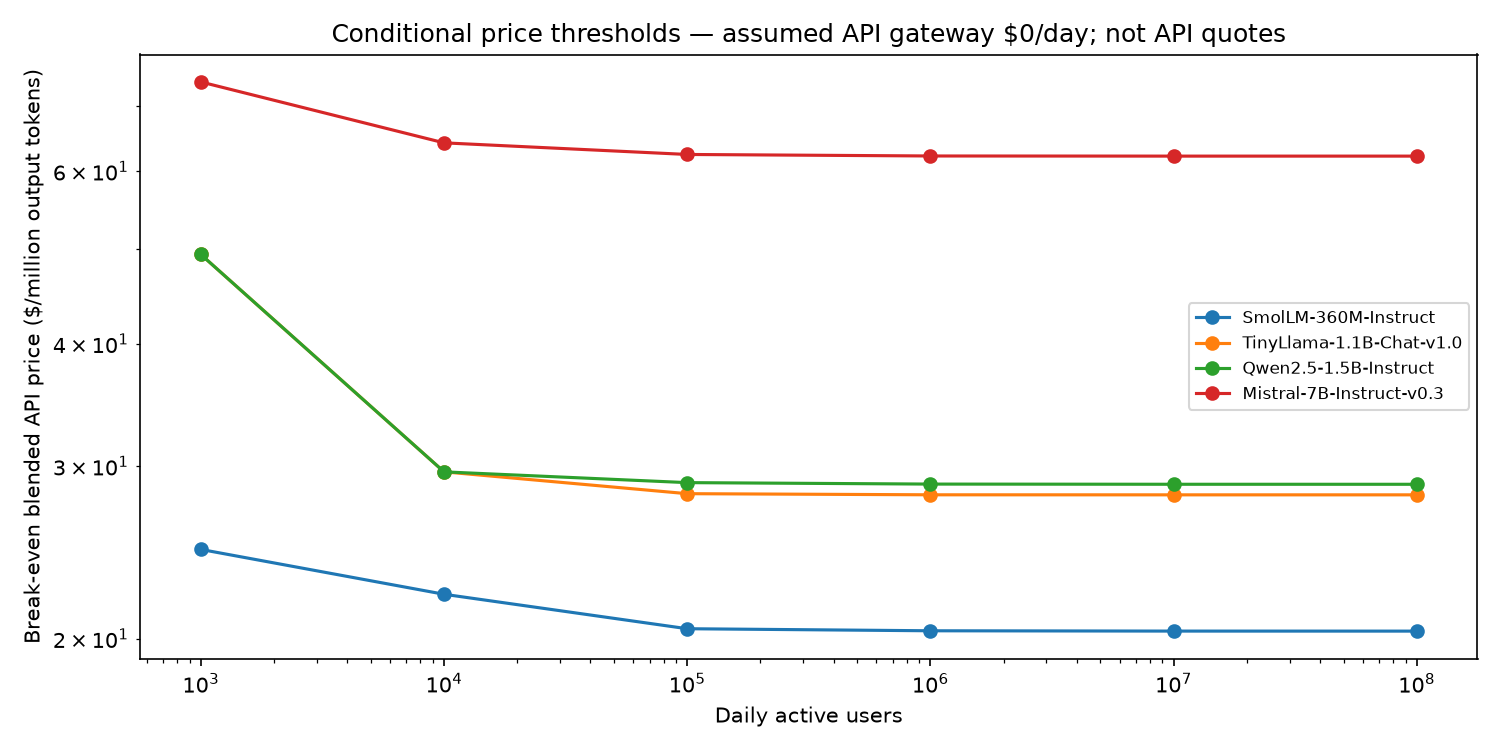

# Step 2.5: local/API cost analysis

Validated 90 workload-aligned daily cost comparisons. API rows reuse one comparable hosted model; this is not measured quality equivalence or 15 exact-model API quotes.

API is cheaper in 90/90 cases; local in 0/90; ties 0.

## Workload, rates and scope

Both tables use one request/user/day, 256 input tokens and 500 output tokens, USD/day, and assumptions ID `hestia-a7-256in-500out-r1-inference-only-v1`. Person 3 uses one comparable `meta-llama/Llama-3.1-8B-Instruct` through Novita/Hugging Face for every local roster model. Reported October 23 catalog rates are $0.02/million input and $0.05/million output tokens, or $0.03012 per 1,000 requests. These supplied historical rates are scenario inputs, not newly verified live quotes or 15 distinct exact-model offers.

Local hosting includes GPU pod compute, disk and a colocated thin handler. API includes token charges and a separate Runpod 2-vCPU gateway with disk ($1.986667/day/replica). Gateway capacity of 50 requests/s is assumed, using shared utilization/peak/service factors. Both exclude the common Django/frontend/database baseline, egress, tax, labor, monitoring and redundancy. Local RTX3090 costs $0.50/hour plus disk under Person 2’s assumptions. Four throughput anchors are measured on T4; eleven are parameter-based estimates. T4-to-3090 capacity transfer is unvalidated. This is inference-tier planning cost, not production TCO.

| DAU | Local daily cost range across 15 alternatives | API daily cost (one comparable) |
|---|---|---|
| 1,000 | $12.333333–$37.000000 | $2.016787 |
| 10,000 | $49.333333–$333.000000 | $2.287867 |
| 100,000 | $431.666667–$3,268.333333 | $4.998667 |
| 1,000,000 | $4,255.000000–$32,671.000000 | $32.106667 |
| 10,000,000 | $42,513.000000–$326,697.666667 | $321.066667 |
| 100,000,000 | $425,093.000000–$3,266,865.666667 | $3,204.706667 |

## Required analysis answers

1. Local is cheaper at none of the six tested traffic levels for any of the 15 alternatives under these supplied assumptions.
2. API is cheaper at all six levels (1k, 10k, 100k, 1m, 10m, 100m DAU). The 15 API alternatives tie because they use the same hosted model and rates.
3. There are 0 observed cheaper-option changes between adjacent levels. No exact DAU crossover is supported. Present costs favor API from launch through the modeled scale; switch toward local only after revised rates/capacity show sustained savings and equivalent task quality, latency and availability. Keep API overflow for temporary peaks, subject to budget and quotas.

The hosted 8B candidate has not run the shared prompts. Price similarity does not establish quality equivalence; a cheap unqualified model cannot replace a qualified route. Huge calculated local fleets and API loads do not establish actual inventory or provider quota availability. Do not sum the 15 mutually exclusive local alternatives as one fleet.

## Separate price sensitivity

`api_rate_frontier.csv` and its figure retain an explicitly zero-gateway sensitivity case. They are not the paired comparison above. For D users, r requests/user, local cost L/day, gateway A/day and input/output rates pi/po in USD per million tokens:

`API/day = A + D*r*(256*pi + 500*po)/1,000,000`.

`b = po + (256/500)*pi; b_break_even = (L-A)*1,000,000/(D*r*500)`.

Local is cheaper above this price threshold; API below it, conditional on comparable quality/scope. Replica ceilings can cause multiple crossings; use all paired points rather than extrapolating one universal break-even.


In [12]:
frontier = pd.read_csv(ROOT/'a7/results/architecture/api_rate_frontier.csv')
display(frontier)
display(Image(filename=str(ROOT/'a7/results/architecture/api_rate_frontier.png')))
display(Markdown((ROOT/'a7/results/architecture/cost_analysis.md').read_text(encoding='utf-8')))


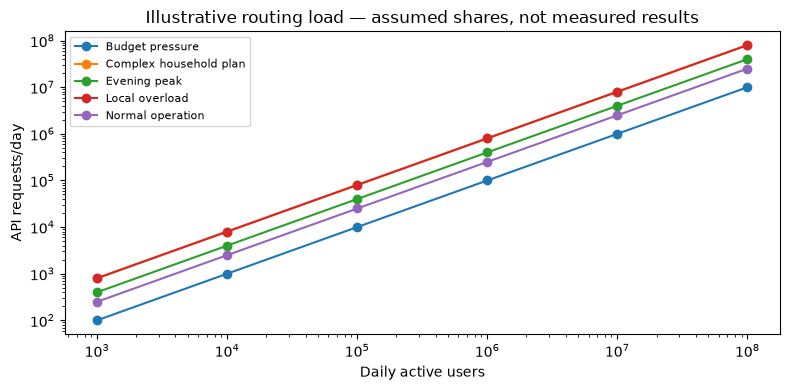

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
for scenario, group in simulation.groupby('scenario'):
    ax.plot(group.daily_active_users, group.api_requests, marker='o', label=scenario)
ax.set(xscale='log', yscale='log', xlabel='Daily active users', ylabel='API requests/day',
       title='Illustrative routing load — assumed shares, not measured results')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Submission status

Architecture lead benchmark: 75/75; team: 375/375. Llama-3.2 completed on an approved-account Colab T4/FP16 run; raw evidence and assistant reviews are preserved. Student signoff on scores remains pending. Cost analysis and three-condition comparison are integrated. Assignment 2 Part 4 is in `slm/architecture_comparison.ipynb` and a Markdown section of the submitted `slm/slm_experiments.ipynb`. Checkpoints are excluded from submission.